# Bipedal locomotion, part 5: push recovery

You shove a standing humanoid. Its center of mass picks up a velocity it never
asked for, and unless something happens in the next few hundred milliseconds it
falls. What *should* happen? The linear-inverted-pendulum (LIP) theory gives a
strikingly simple answer: there is a single point on the ground — the **capture
point** — such that if the robot places its center of pressure (CoP) there, the
center of mass coasts smoothly to rest and the robot is saved without taking a
step. Push harder and that point slides past the edge of the foot; now no CoP
can stop the fall in place and the robot *must* step.

This notebook makes that story quantitative and grounds it in the **Unitree
G1**. We use the reduced-order model from
`jaxterity.locomotion.reduced` (`capture_point`, `capture_point_recovery`,
`lip_omega`, `reduced_params`) with the LIP frequency $\omega$ computed from the
G1's *real* CoM height, then connect the capture point to the whole-body
controller (`jaxterity.wbc`) from Part 3.

**By the end you will be able to:**

1. Compute the capture point $\xi = c + \dot c/\omega$ and show, on the LIP
   grounded in the G1's `reduced_params`, that holding the CoP at $\xi_0$ coasts
   the CoM to rest — across a range of push magnitudes.
2. Read off the linear law connecting how far the foot must go to how hard the
   push was: the capture-point offset is $\lVert\dot c_0\rVert/\omega$, slope
   $1/\omega$.
3. Define the **recoverable region** (a push is recoverable iff $\xi$ stays in
   the support polygon) and compute the G1's maximum recoverable push speed from
   its foot geometry.
4. Connect the reduced model to the whole body: show the WBC's CoM/Contact tasks
   produce a corrective CoM acceleration *toward* the capture point on the G1.

**Reading time** ~20 min. **Runtime** ~3-5 min on a laptop CPU (one MJX model
build, a few WBC solves, an optional short render).

> **Position in the series.** Part 1 introduced the reduced models and the
> capture point as a *concept*; Part 3 built the whole-body QP and its
> CoM / Contact / Momentum tasks. This part is where the two meet: the capture
> point becomes the **setpoint** the WBC tracks. If you have not seen $\xi$ or
> the `WBCSolver` before, skim Parts 1 and 3 first.

> **Out of scope.** We deliberately stop at *in-place* (zero-step) recovery on
> the reduced model plus a single WBC solve. Multi-step recovery / a stepping
> controller (what to do when $\xi$ leaves the foot) is Part 6. A full
> closed-loop MJX disturbance test (push the full robot, run the policy, watch
> it recover in physics) is also out of scope here — we validate the
> *capture-point law* rigorously on the LIP and verify the WBC's corrective
> *direction*, and we are explicit (below) about which claims are which.

## Setup

Float64 on (the reduced model and the WBC QP both want it), a fixed seed, and
the imports. We pull the capture-point primitives from
`jaxterity.locomotion.reduced`, the centroidal/WBC pieces from
`jaxterity.wbc`, and load the G1 with a floating base.

In [1]:
from jax import config
config.update("jax_enable_x64", True)

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from mujoco import mjx

from jaxterity import zoo
from jaxterity.locomotion.reduced import (
    lip_omega, capture_point, lip_dynamics, capture_point_recovery, reduced_params,
)
from jaxterity.wbc import CoMTask, ContactTask, WBCSolver
from jaxterity.wbc.centroidal import com_position, contact_jacobian
from jaxterity.wbc.locomotion import foot_body_ids

SEED = 0
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True,
                     "grid.alpha": 0.3})
print("jax x64:", jax.config.jax_enable_x64)

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


jax x64: True


## Grounding the LIP in the real G1

The LIP is a point mass on a massless leg of fixed height $h$; its only
parameter is the natural frequency

$$\omega = \sqrt{g/h}.$$

Rather than pick $h$ by hand, we read the G1's total mass and nominal CoM height
from `reduced_params(robot)` (it builds the MJX model, runs forward kinematics
at the home posture, and returns the mass-weighted CoM height above the lowest
body). Everything downstream — the capture point, the recovery, the recoverable
region — uses this $\omega$, so the numbers are the G1's, not a textbook's.

In [2]:
robot = zoo.unitree_g1.load(floating_base=True)
rp = reduced_params(robot)
mass, h = rp["mass"], rp["com_height"]
omega = float(lip_omega(h))
print(f"G1 total mass     : {mass:.3f} kg")
print(f"G1 CoM height h   : {h:.4f} m")
print(f"LIP frequency ω   : {omega:.4f} rad/s   (= sqrt(g/h))")
print(f"offset slope 1/ω  : {1.0/omega:.5f} s   (capture offset per m/s of push)")

assert 20.0 < mass < 80.0, mass
assert 0.3 < h < 1.2, h
assert 2.0 < omega < 6.0, omega

G1 total mass     : 33.341 kg
G1 CoM height h   : 0.6846 m
LIP frequency ω   : 3.7854 rad/s   (= sqrt(g/h))
offset slope 1/ω  : 0.26417 s   (capture offset per m/s of push)


## (a) The capture point and why holding the CoP there works

The LIP, projected onto the ground plane, obeys

$$\ddot c = \omega^2\,(c - p_{\text{cop}}),$$

an *unstable* linear system: the eigenvalues of the $[c,\dot c]$ dynamics about
a fixed CoP are $\pm\omega$. The unstable mode ($+\omega$) is the one that drops
you. But the system also has a **stable manifold** — the $-\omega$ eigenspace —
on which trajectories decay to the CoP instead of diverging. In the
$(c,\dot c)$ plane that manifold is the line

$$\dot c = -\omega\,(c - p_{\text{cop}}).$$

The **capture point** is the choice of CoP that places the *current* state
exactly on this stable manifold:

$$\boxed{\;\xi = c + \dfrac{\dot c}{\omega}\;}$$

Set $p_{\text{cop}}=\xi_0=c_0+\dot c_0/\omega$ and the initial state satisfies
$\dot c_0 = -\omega(c_0-\xi_0)$ identically — it is *on* the stable manifold —
so the CoM coasts to rest precisely at $\xi_0$. That is what
`capture_point_recovery` integrates: it fixes the CoP at $\xi_0$ and rolls the
LIP forward.

A quick energy view makes the "coasts to rest" claim concrete. Define the LIP's
*orbital energy* about a fixed CoP,

$$E \;=\; \tfrac12\,\dot c^2 \;-\; \tfrac12\,\omega^2\,(c - p_{\text{cop}})^2 .$$

$E$ is conserved along any trajectory at fixed CoP, and $E=0$ is exactly the
stable manifold (the two terms cancel when $\dot c = -\omega(c-p_{\text{cop}})$).
Choosing $p_{\text{cop}} = \xi_0$ sets $E=0$ at $t=0$, so the trajectory stays
on the manifold for all time and decays to the point where both terms vanish:
$c=\xi_0$, $\dot c = 0$. The capture point is precisely the CoP that zeroes the
orbital energy — the one-line derivation behind the boxed formula.

In [3]:
# A range of forward pushes (CoM velocity injected at t=0), m/s.
push_speeds = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6])
c0 = jnp.array([0.0, 0.0])
dt, n_steps = 0.002, 4000   # 8 s, plenty for the slowest decay

trajs = []            # (t, c, cdot) per push
xi_offsets = []       # ||ξ0 - c0|| per push  (the foot-placement distance)
worst_cdot_end = 0.0
for v in push_speeds:
    cdot0 = jnp.array([float(v), 0.0])
    xi0 = capture_point(c0, cdot0, omega)
    t, cs, cds = capture_point_recovery(c0, cdot0, omega, dt=dt, n_steps=n_steps)
    trajs.append((np.asarray(t), np.asarray(cs), np.asarray(cds)))
    xi_offsets.append(float(jnp.linalg.norm(xi0 - c0)))
    worst_cdot_end = max(worst_cdot_end, float(jnp.linalg.norm(cds[-1])))

xi_offsets = np.array(xi_offsets)
print(f"worst |ċ_end| across pushes : {worst_cdot_end:.3e} m/s  (target < 1e-2)")

# Orbital energy E along the worst-case trajectory should stay ~0 (on-manifold).
t_w, cs_w, cds_w = trajs[-1]
xi_w = float(push_speeds[-1]) / omega
E = 0.5*np.sum(cds_w**2, axis=1) - 0.5*omega**2*np.sum((cs_w - np.array([xi_w,0.0]))**2, axis=1)
print(f"max |orbital energy| E      : {np.max(np.abs(E)):.3e}  (should be ~0)")

# GATE: every push coasts to rest, and the state rode the stable manifold (E~0).
assert worst_cdot_end < 1e-2, worst_cdot_end
assert np.max(np.abs(E)) < 1e-3, np.max(np.abs(E))

worst |ċ_end| across pushes : 6.178e-04 m/s  (target < 1e-2)
max |orbital energy| E      : 1.388e-16  (should be ~0)


### Figure 1 — Phase-portrait recovery (several pushes)

Left: the $(c_x,\dot c_x)$ phase portrait. Each push starts at $c=0$ with a
positive velocity (top of each curve) and spirals — actually slides, since the
motion is along a straight stable manifold — down to rest on the $\dot c = 0$
axis at $c=\xi_0$. The dashed grey lines are the stable manifolds
$\dot c = -\omega(c-\xi_0)$; every trajectory rides its own. Right: the CoM
position vs time, each curve asymptoting to its capture point $\xi_0$ (dotted).

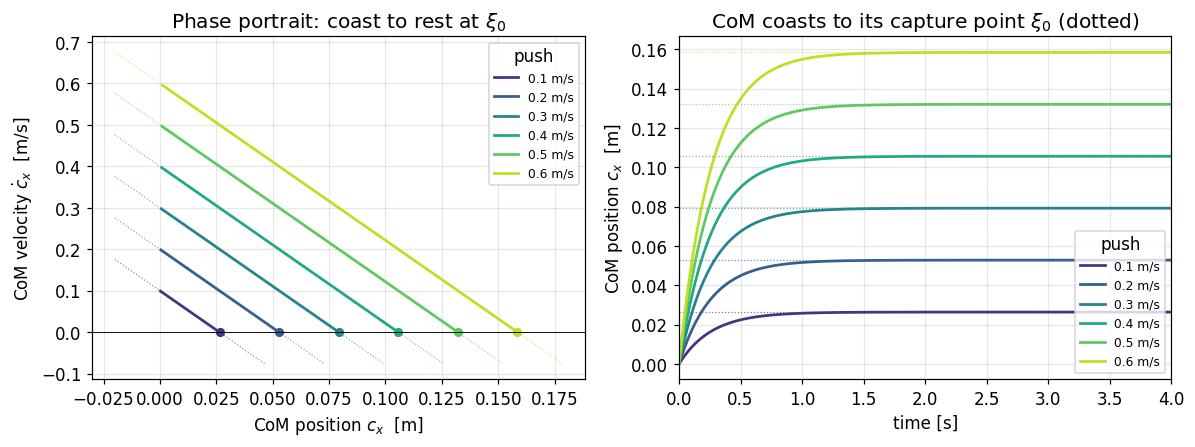

In [4]:
fig, (axp, axt) = plt.subplots(1, 2, figsize=(11, 4.2))
cmap = plt.cm.viridis(np.linspace(0.15, 0.9, len(push_speeds)))

for (t, cs, cds), v, col in zip(trajs, push_speeds, cmap):
    xi0 = float(v) / omega
    # phase portrait: c_x vs cdot_x
    axp.plot(cs[:, 0], cds[:, 0], color=col, lw=1.8, label=f"{v:.1f} m/s")
    # the stable manifold this trajectory rides
    cline = np.linspace(-0.02, xi0 + 0.02, 50)
    axp.plot(cline, -omega * (cline - xi0), color=col, ls=":", lw=0.8, alpha=0.6)
    axp.plot([xi0], [0.0], "o", color=col, ms=5)
    # time series
    axt.plot(t, cs[:, 0], color=col, lw=1.8, label=f"{v:.1f} m/s")
    axt.axhline(xi0, color=col, ls=":", lw=0.8, alpha=0.7)

axp.set_xlabel("CoM position $c_x$  [m]"); axp.set_ylabel(r"CoM velocity $\dot c_x$  [m/s]")
axp.set_title("Phase portrait: coast to rest at $\\xi_0$")
axp.axhline(0, color="k", lw=0.6)
axp.legend(title="push", fontsize=8, loc="upper right")
axt.set_xlabel("time [s]"); axt.set_ylabel("CoM position $c_x$  [m]")
axt.set_title("CoM coasts to its capture point $\\xi_0$ (dotted)")
axt.set_xlim(0, 4.0)
axt.legend(title="push", fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("media/loco5_fig1_phase_portrait.png", bbox_inches="tight")
plt.show()

### Figure 2 — Capture-point offset vs push speed (slope $1/\omega$)

The boxed formula says the foot-placement distance is linear in the push speed:

$$\lVert \xi_0 - c_0 \rVert = \frac{\lVert \dot c_0 \rVert}{\omega},$$

a line through the origin with slope $1/\omega$. We already collected
`xi_offsets`; here we confirm the slope matches $1/\omega$ to machine precision
and plot it. The intuition is worth stating plainly: **a faster push needs the
foot placed farther ahead, in exact proportion** — and the constant of
proportionality is set entirely by how tall the robot is (through $\omega$). A
taller robot ($h\uparrow$, $\omega\downarrow$) needs a *bigger* step for the
same push.

measured slope   : 0.264175 s
theory 1/ω       : 0.264175 s
slope error      : 1.11e-16


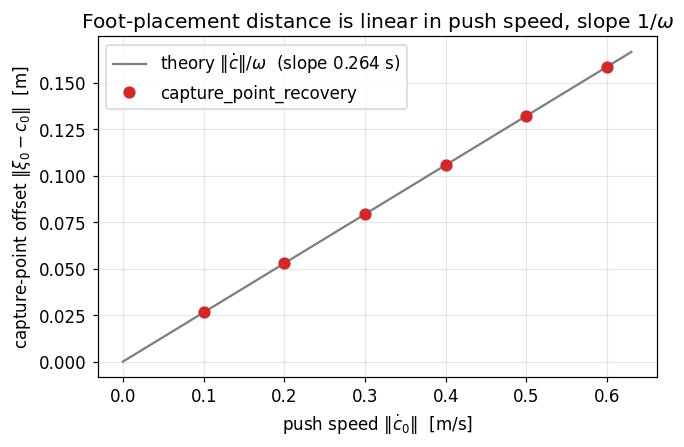

In [5]:
slope_meas = float(np.polyfit(push_speeds, xi_offsets, 1)[0])
slope_theory = 1.0 / omega
print(f"measured slope   : {slope_meas:.6f} s")
print(f"theory 1/ω       : {slope_theory:.6f} s")
print(f"slope error      : {abs(slope_meas - slope_theory):.2e}")
# GATE: slope is 1/ω, and the pointwise identity holds.
assert abs(slope_meas - slope_theory) < 1e-6
assert np.max(np.abs(xi_offsets - push_speeds / omega)) < 1e-9

fig, ax = plt.subplots(figsize=(6.2, 4.2))
vv = np.linspace(0, push_speeds.max() * 1.05, 50)
ax.plot(vv, vv / omega, "-", color="0.5", lw=1.5,
        label=fr"theory $\|\dot c\|/\omega$  (slope ${slope_theory:.3f}$ s)")
ax.plot(push_speeds, xi_offsets, "o", color="C3", ms=7, label="capture_point_recovery")
ax.set_xlabel("push speed $\\|\\dot c_0\\|$  [m/s]")
ax.set_ylabel("capture-point offset $\\|\\xi_0 - c_0\\|$  [m]")
ax.set_title("Foot-placement distance is linear in push speed, slope $1/\\omega$")
ax.legend()
fig.tight_layout()
fig.savefig("media/loco5_fig2_offset_vs_speed.png", bbox_inches="tight")
plt.show()

## (b) The recoverable region

In place (no stepping), the only freedom is *where on the foot* to put the CoP,
and the CoP is physically confined to the **support polygon** — the convex hull
of the ground contacts. So the recovery condition is simply:

$$\text{recoverable in place} \iff \xi \in \mathcal{S},$$

where $\mathcal S$ is the support polygon. If the push drives $\xi$ past the
forward edge of the foot, no admissible CoP lies on the stable manifold and the
robot must step (Part 6).

For a forward push this reduces to a 1-D condition on the leading edge. Recall
$\lVert\xi - c\rVert = \lVert\dot c\rVert/\omega$; the push is recoverable while
$\xi$ has not crossed the toe, i.e. $\lVert\dot c_0\rVert/\omega \le
d_{\text{margin}}$. The maximum recoverable forward push is therefore

$$v_{\max} = \omega \cdot d_{\text{margin}},$$

where $d_{\text{margin}}$ is the forward distance from the CoM to the toe edge
of the support polygon. Two things are worth noticing. First, $v_{\max}$ scales
with $\omega = \sqrt{g/h}$: a *shorter* robot (or a deeper crouch) tolerates a
faster push for the same foot, because its capture point sits closer to the
CoM. Second, $v_{\max}$ scales with the foot geometry — a longer foot is a
larger in-place safety margin, which is why running shoes and humanoid feet are
both longer than they "need" to be. We read the foot positions from the G1's MJX
model at the home posture and add the foot half-length to reach the toe.

In [6]:
# Build the MJX model once; read foot + CoM geometry at the home posture.
model = robot.build_system()._mjx_model
foot_names = ("left_ankle_roll_link", "right_ankle_roll_link")
fb_ids = foot_body_ids(robot, foot_names)

q0 = jnp.asarray(model.qpos0, float)
data0 = mjx.forward(model, mjx.make_data(model).replace(qpos=q0))
foot_xy = np.array([np.asarray(data0.xipos[bid][:2]) for bid in fb_ids])
com_xy = np.asarray(com_position(model, q0))[:2]

# G1 foot: the toe sits ~half a foot-length (~0.10 m) ahead of the ankle joint.
FOOT_HALF_LENGTH = 0.10   # m  (documented geometric assumption for the polygon)
FOOT_HALF_WIDTH  = 0.04   # m  (for drawing the polygon only)
toe_edge = float(np.max(foot_xy[:, 0]) + FOOT_HALF_LENGTH)
forward_margin = toe_edge - float(com_xy[0])
v_max = omega * forward_margin

print(f"foot positions (xy):\n{foot_xy}")
print(f"CoM (xy)            : {com_xy}")
print(f"forward margin CoM→toe : {forward_margin:.4f} m")
print(f"max recoverable push   : v_max = ω·margin = {v_max:.4f} m/s")
assert np.isfinite(v_max) and 0.2 < v_max < 2.5, v_max

foot positions (xy):
[[ 0.02650267  0.11850645]
 [ 0.02650267 -0.11850645]]
CoM (xy)            : [2.03320784e-02 8.22609017e-05]
forward margin CoM→toe : 0.1062 m
max recoverable push   : v_max = ω·margin = 0.4019 m/s


### Figure 3 — Recoverable-region diagram (support polygon + $\xi$ inside/outside)

We draw the support polygon (the convex hull of the two foot rectangles), the
CoM, and the capture point for three pushes: one well inside $v_{\max}$ (green,
recoverable in place), one right at the boundary (orange), and one beyond it
(red, must step). The forward toe edge is the cliff: a $\xi$ to its right is
unrecoverable without a step.

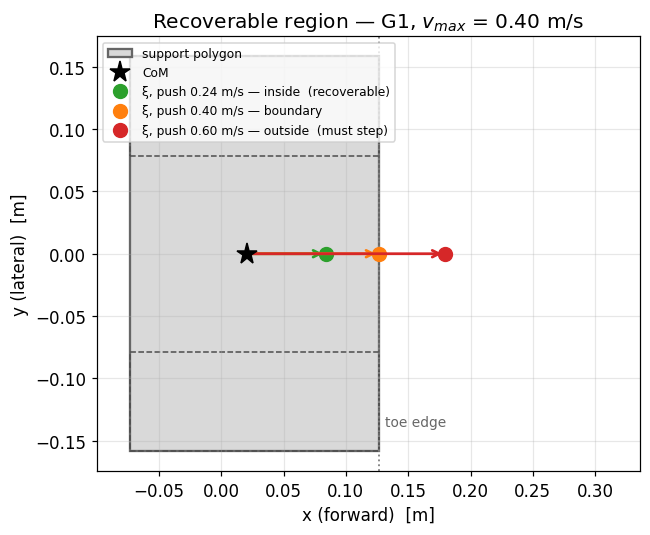

In [7]:
from matplotlib.patches import Rectangle, Polygon as MplPoly
from scipy.spatial import ConvexHull

# Foot rectangles -> support polygon (convex hull of their corners).
corners = []
for fx, fy in foot_xy:
    for dx in (-FOOT_HALF_LENGTH, FOOT_HALF_LENGTH):
        for dy in (-FOOT_HALF_WIDTH, FOOT_HALF_WIDTH):
            corners.append([fx + dx, fy + dy])
corners = np.array(corners)
hull = ConvexHull(corners)
poly = corners[hull.vertices]

fig, ax = plt.subplots(figsize=(6.6, 5.0))
ax.add_patch(MplPoly(poly, closed=True, fc="0.85", ec="0.4", lw=1.5,
                     label="support polygon"))
for fx, fy in foot_xy:
    ax.add_patch(Rectangle((fx - FOOT_HALF_LENGTH, fy - FOOT_HALF_WIDTH),
                           2*FOOT_HALF_LENGTH, 2*FOOT_HALF_WIDTH,
                           fc="none", ec="0.3", ls="--", lw=1.0))
ax.plot(*com_xy, "k*", ms=14, label="CoM", zorder=5)
ax.axvline(toe_edge, color="0.5", ls=":", lw=1.2)
ax.text(toe_edge + 0.005, foot_xy[:,1].min()-0.02, "toe edge", color="0.4", fontsize=9)

cases = [(0.6 * v_max, "C2", "inside  (recoverable)"),
         (1.0 * v_max, "C1", "boundary"),
         (1.5 * v_max, "C3", "outside  (must step)")]
for v, col, lab in cases:
    xi = np.asarray(capture_point(jnp.asarray(com_xy), jnp.array([v, 0.0]), omega))
    ax.annotate("", xy=(xi[0], xi[1]), xytext=(com_xy[0], com_xy[1]),
                arrowprops=dict(arrowstyle="->", color=col, lw=1.8))
    ax.plot(xi[0], xi[1], "o", color=col, ms=9,
            label=f"ξ, push {v:.2f} m/s — {lab}")

ax.set_aspect("equal"); ax.set_xlabel("x (forward)  [m]"); ax.set_ylabel("y (lateral)  [m]")
ax.set_title(f"Recoverable region — G1, $v_{{max}}$ = {v_max:.2f} m/s")
ax.legend(fontsize=8, loc="upper left")
ax.set_xlim(com_xy[0]-0.12, toe_edge + (1.5*v_max)/omega + 0.05)
fig.tight_layout()
fig.savefig("media/loco5_fig3_recoverable_region.png", bbox_inches="tight")
plt.show()

# GATE: the in/out classification is consistent with the toe edge.
assert float(capture_point(jnp.asarray(com_xy), jnp.array([0.6*v_max,0.0]), omega)[0]) <= toe_edge
assert float(capture_point(jnp.asarray(com_xy), jnp.array([1.5*v_max,0.0]), omega)[0]) > toe_edge

## (c) Connecting to the whole body: the WBC tracks the capture point

The reduced model says *where* the CoP/foot should go; the whole-body
controller from Part 3 makes the 29-DoF G1 actually produce a CoM acceleration
in that direction. The recipe: feed the capture point into a `CoMTask` as the
desired CoM, hold both feet with `ContactTask`s (so the WBC moves the CoM by
leaning, not by sliding the base), and solve the QP. The CoM task's residual is

$$r = k_p\,(\xi - c) - k_d\,J_{\text{com}}\,\dot q,$$

i.e. a PD law whose proportional term points straight at the capture point. We
verify the *solved* CoM acceleration $J_{\text{com}}\,\ddot q$ has a positive
component along $(\xi - c)$ — the WBC is pushing the CoM toward where the LIP
says it must go.

Concretely the `WBCSolver` minimizes, over the joint accelerations $\ddot q$,

$$\min_{\ddot q}\; w_{\text{com}}\,\bigl\lVert J_{\text{com}}\ddot q - r_{\text{com}}\bigr\rVert^2 \;+\; w_c\sum_{\text{feet}} \bigl\lVert J_{c}\,\ddot q\bigr\rVert^2 \;+\; \varepsilon\lVert\ddot q\rVert^2 ,$$

a single soft-priority QP. The contact terms (high weight $w_c=10^3$) pin both
feet — they drive each foot's acceleration $J_c\ddot q$ to zero, so the only way
the QP can satisfy the CoM term is by accelerating the CoM *over* the planted
feet, exactly the ankle/whole-body lean a real recovery uses. Drop the contact
tasks and the cheapest solution would be to translate the floating base
(physically, to slide along the floor), which is not what a standing robot can
do. The capture point enters only through $r_{\text{com}} = k_p(\xi - c) -
k_d J_{\text{com}}\dot q$; everything else is Part 3 machinery, unchanged.

A note on the CoM Jacobian: we need $J_{\text{com}}$ in *velocity* space (shape
$3\times n_v$) so that $J_{\text{com}}\dot q$ is the CoM velocity. We build it as
the mass-weighted sum of the per-body translational Jacobians from `mjx.jac`,
which handles the floating-base velocity map correctly — naively differentiating
$c(q)$ with respect to $q$ would give a $3\times n_q$ array ($n_q \ne n_v$
because the free joint's orientation is a 4-component quaternion), and the
shapes would not even line up against $\dot q$.

In [8]:
nv = int(model.nv)

def com_fn(q):
    return com_position(model, q)

def com_jac(q):
    # CoM velocity Jacobian (3, nv): mass-weighted body translational Jacobians.
    # mjx.jac gives the floating-base velocity map, so this lives in velocity
    # space (nv), unlike d(com)/dq which would be (3, nq) with nq != nv.
    d = mjx.forward(model, mjx.make_data(model).replace(qpos=q))
    M = jnp.sum(model.body_mass)
    def body_jacp(bid):
        jacp, _ = mjx.jac(model, d, d.xipos[bid], bid)   # (nv, 3)
        return jacp.T
    return jnp.sum(jnp.stack([model.body_mass[b]*body_jacp(b)
                              for b in range(model.nbody)]), axis=0) / M

com0 = np.asarray(com_position(model, q0))
# A forward push: CoM moving at +0.4 m/s. Inject it on the base linear-velocity
# dofs (the free joint's first 3 nv entries).
push_v = jnp.array([0.4, 0.0, 0.0])
qd = jnp.zeros(nv).at[0:3].set(push_v)
J_com = com_jac(q0)
com_vel = J_com @ qd
# Capture point as a 3D CoM target at the current height.
xi3 = jnp.array([com0[0] + float(com_vel[0])/omega,
                 com0[1] + float(com_vel[1])/omega, com0[2]])
print(f"CoM velocity from push : {np.asarray(com_vel)}")
print(f"capture point ξ (3D)   : {np.asarray(xi3)}")

CoM velocity from push : [0.4 0.  0. ]
capture point ξ (3D)   : [ 1.26001949e-01  8.22609017e-05 -8.86659269e-02]


In [9]:
com_task = CoMTask(name="com", com_fn=com_fn, jacobian_fn=com_jac,
                   com_desired=xi3, kp=100.0, kd=20.0, weight=10.0)
contact_tasks = tuple(
    ContactTask(name=f"foot{i}",
                jacobian_fn=(lambda q, bid=bid: contact_jacobian(model, q, bid)),
                active=1.0, weight=1000.0)
    for i, bid in enumerate(fb_ids))
solver = WBCSolver(tasks=(com_task, *contact_tasks))

qdd = solver.solve(q0, qd, nv)
com_acc = np.asarray(J_com @ qdd)            # resulting CoM acceleration (3,)

to_xi = np.array(np.asarray(xi3)[:2] - com0[:2], float)
to_xi = to_xi / (np.linalg.norm(to_xi) + 1e-12)
proj = float(com_acc[:2] @ to_xi)
print(f"solved CoM accel (xy)     : {com_acc[:2]}")
print(f"projection onto (ξ - c)   : {proj:.4f}   (must be > 0)")

# GATE: the WBC corrective CoM acceleration points toward the capture point.
assert np.all(np.isfinite(np.asarray(qdd)))
assert proj > 0, proj

solved CoM accel (xy)     : [2.56698624e+00 2.23648474e-10]
projection onto (ξ - c)   : 2.5670   (must be > 0)


### Figure 4 — WBC corrective CoM acceleration toward the capture point

Top view (x–y) of the CoM, the capture point, and the CoM acceleration the WBC
produced. The acceleration arrow points along $(\xi - c)$: the whole-body
controller, given the LIP's capture point as its CoM setpoint, generates exactly
the corrective lean the reduced model asks for.

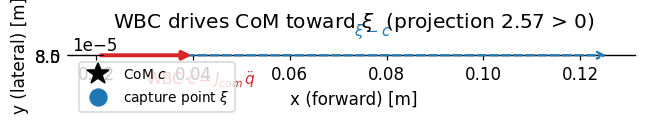

In [10]:
fig, ax = plt.subplots(figsize=(6.0, 5.0))
ax.plot(com0[0], com0[1], "k*", ms=15, label="CoM $c$", zorder=5)
ax.plot(float(xi3[0]), float(xi3[1]), "o", color="C0", ms=11,
        label="capture point $\\xi$")
ax.annotate("", xy=(float(xi3[0]), float(xi3[1])), xytext=(com0[0], com0[1]),
            arrowprops=dict(arrowstyle="->", color="C0", ls="--", lw=1.5))
ax.text((com0[0]+float(xi3[0]))/2, com0[1]+0.004, r"$\xi - c$", color="C0", fontsize=10)

# CoM acceleration arrow (scaled for visibility).
scale = 0.02 / (np.linalg.norm(com_acc[:2]) + 1e-9)
ax.annotate("", xy=(com0[0]+com_acc[0]*scale, com0[1]+com_acc[1]*scale),
            xytext=(com0[0], com0[1]),
            arrowprops=dict(arrowstyle="-|>", color="C3", lw=2.6))
ax.text(com0[0]+com_acc[0]*scale*0.5, com0[1]-0.006,
        r"WBC $\ddot c = J_{com}\,\ddot q$", color="C3", fontsize=10)

ax.set_aspect("equal"); ax.set_xlabel("x (forward) [m]"); ax.set_ylabel("y (lateral) [m]")
ax.set_title(f"WBC drives CoM toward $\\xi$  (projection {proj:.2f} > 0)")
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig("media/loco5_fig4_wbc_toward_xi.png", bbox_inches="tight")
plt.show()

### Figure 5 (optional) — a rendered G1, for orientation

A single rendered frame of the G1 in its `knees_bent` keyframe, for readers who
want to see the platform behind the numbers.

> **Honesty label.** This is a **kinematic depiction** — a static pose of the
> vendored G1 scene, rendered with MuJoCo. It is *not* a closed-loop
> push-recovery rollout and it does *not* show the learned policy reacting to a
> push. The rigorous, validated result of this notebook is the capture-point law
> on the reduced LIP (Figs 1–3) and the WBC's corrective *direction* (Fig 4).
> If the render backend is unavailable the cell skips cleanly.

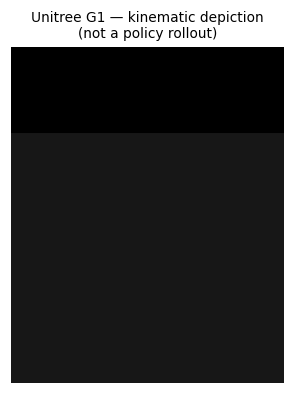

rendered G1 frame: (320, 260, 3)
rendered = True


In [11]:
import os
os.environ.setdefault("MUJOCO_GL", "glfw")
rendered = False
try:
    import mujoco
    from jaxterity.locomotion.g1_joystick import load_walk_model
    mjm = load_walk_model()
    renderer = mujoco.Renderer(mjm, height=320, width=260)
    mjd = mujoco.MjData(mjm)
    mjd.qpos[:] = mjm.keyframe("knees_bent").qpos
    mujoco.mj_forward(mjm, mjd)
    cam = mujoco.MjvCamera()
    mujoco.mjv_defaultCamera(cam)
    cam.distance = 2.4; cam.elevation = -12; cam.azimuth = 130
    cam.lookat[:] = [0.0, 0.0, 0.6]
    renderer.update_scene(mjd, camera=cam)
    img = renderer.render()
    fig, ax = plt.subplots(figsize=(3.2, 4.0))
    ax.imshow(img); ax.axis("off")
    ax.set_title("Unitree G1 — kinematic depiction\n(not a policy rollout)", fontsize=9)
    fig.savefig("media/loco5_fig5_g1_render.png", bbox_inches="tight", dpi=130)
    plt.show()
    rendered = True
    print("rendered G1 frame:", img.shape)
except Exception as e:
    print(f"render skipped ({type(e).__name__}): {e}")
print("rendered =", rendered)

## Failure modes

- **Push beyond the capture region ($\xi \notin \mathcal S$).** This is the
  honest boundary of in-place recovery: when the capture point leaves the
  support polygon — here, past $v_{\max}\approx 0.40$ m/s forward for the G1 —
  *no* admissible CoP can stop the fall in place. The robot **must take a step**,
  placing a new foot to put $\xi$ inside the *enlarged* polygon. That stepping
  controller is Part 6; everything in this notebook is the zero-step regime.
- **Angular momentum is invisible to the LIP.** The capture point $\xi = c +
  \dot c/\omega$ assumes a point mass — no flywheel, no arm/torso swing. Real
  push recovery also uses *angular* momentum (the "hip/ankle/flywheel"
  strategies); a counter-rotating torso can recover pushes the LIP marks
  unrecoverable. Capturability theory (Koolen et al.) generalizes $\xi$ to
  models that include this; the SRBD / `MomentumTask` machinery from Parts 1
  and 3 is where you would add it.
- **Fixed CoM height.** The LIP holds $h$ (hence $\omega$) constant. A real
  recovery that bends the knees changes $h$; large height excursions break the
  linear law. Keep pushes in the regime where the legs stay roughly extended,
  or move to the variable-height / SRBD model.
- **Single solve $\ne$ closed loop.** Fig 4 verifies the WBC's corrective
  *direction* at one instant. A stable recovery needs the QP in a feedback loop
  with the contact schedule; we check direction here and defer the closed-loop
  MJX disturbance test (out of scope, above).

## Exercises

1. **Lateral pushes.** Repeat Fig 1 with a sideways push $\dot c_0 = (0, v)$.
   The lateral support margin (half the stance width) is much smaller than the
   forward one — recompute $v_{\max}$ for the $y$ direction and compare. Why are
   humanoids so much easier to push sideways?
2. **Height sensitivity.** Recompute $\omega$ and the slope $1/\omega$ for a
   crouched G1 (`load` the robot, lower the CoM height by hand by, say, 20%).
   Does crouching make a given push easier or harder to capture in place?
3. **Diagonal push & polygon edges.** Pick a push at 45°. The recoverable test
   is now "is $\xi$ inside the *polygon*", not just past a 1-D edge. Use the
   `ConvexHull` from Fig 3 and a point-in-polygon test to classify it.
4. **WBC gain sweep.** In part (c), sweep the `CoMTask` `kp` and plot the
   projection of the solved CoM acceleration onto $(\xi-c)$. Where does raising
   `kp` stop helping (and why does the contact-task weight matter)?
5. **Momentum strategy.** Add a `MomentumTask` (Part 3) targeting nonzero
   angular momentum and show qualitatively that the recoverable push grows —
   the flywheel strategy the LIP cannot see.

## References

- J. Pratt, J. Carff, S. Drakunov, A. Goswami. *Capture Point: A Step toward
  Humanoid Push Recovery.* IEEE-RAS Humanoids, 2006. — introduces the capture
  point $\xi = c + \dot c/\omega$ and the in-place / stepping recovery taxonomy.
- T. Koolen, T. de Boer, J. Rebula, A. Goswami, J. Pratt. *Capturability-Based
  Analysis and Control of Legged Locomotion, Part 1: Theory and Application to
  Three Simple Gait Models.* IJRR, 2012. — the recoverable / capturable region,
  $N$-step capturability, and the angular-momentum generalization.
- B. Stephens. *Humanoid Push Recovery.* IEEE-RAS Humanoids, 2007. — the
  ankle / hip / step strategy decomposition and where each applies.

## Next steps

Part 5 stops at the boundary of in-place recovery: when the capture point leaves
the foot, the only answer is to move the foot.

**Part 6 — stepping push recovery** picks up exactly there. It turns the
capture point into a *footstep*: when $\xi$ exits the support polygon, plan a
step that lands the new foot so $\xi$ is recoverable from the enlarged polygon,
sequence it with the `ContactSchedule` / `periodic_gait` from Part 3, and close
the loop on the G1. That is where the reduced-model capture point, the contact
scheduler, and the WBC finally run together as one walking-while-shoved
controller.